In [1]:
from numpy import *
from matplotlib.pyplot import *
import math
from scipy.stats import skewnorm
from scipy import interpolate
import numpy.ma as ma
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import interp1d
from scipy import signal
from scipy.optimize import curve_fit
from astropy.convolution import Box1DKernel,convolve
from scipy.stats import chisquare
import your
import glob,os
from frb_functions import *
from scipy.signal import find_peaks

## This notebook just reproduces the plots of bursts in the paper. Each burst is plotted individually, and then the figures combined separately in a pdf editor (I used Keynote).

In [2]:
# defining fitting functions

def exponential(x, tau): 
    # one-sided exponential
    piece = piecewise(x,[x<0,x>=0],[0,exp(-x[x>=0]/tau)])/tau
    return piece

def gaussian(x, mu, sig):
    # simple gaussian
    return exp(-power(x - mu, 2.) / (2 * power(sig, 2.)))

def pulse_shape(x, tau, mu, sig, A, F, mu2, sig2, A2):
    # two-component burst, different Gaussian widths but same scattering time
    half = int(len(x)/2)
    ex = piecewise(x,[x<mu,x>=mu],[0,exp(-x[x>=mu]/tau)])
    gauss = exp(-power(x - mu, 2.) / (2 * power(sig, 2.)))
    full = np.convolve(ex,gauss,mode='same')
    
    ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
    gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
    full2 = np.convolve(ex2,gauss2,mode='same')
    return A*full + A2*full2 + F

def pulse_shape3(x, tau, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3):
    # three-component burst
    half = int(len(x)/2)
    ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
    gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
    full = np.convolve(ex,gauss,mode='same')
    
    ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
    gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
    full2 = np.convolve(ex2,gauss2,mode='same')

    ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
    gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
    full3 = np.convolve(ex3,gauss3,mode='same')
    return A1*full + A2*full2 + A3*full3 + F1

def pulse_shape4(x, tau, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3, mu4, sig4, A4):
    # four-component burst
    half = int(len(x)/2)
    ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
    gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
    full = np.convolve(ex,gauss,mode='same')
    
    ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
    gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
    full2 = np.convolve(ex2,gauss2,mode='same')

    ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
    gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
    full3 = np.convolve(ex3,gauss3,mode='same')

    ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
    gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
    full4 = np.convolve(ex4,gauss4,mode='same')
    return A1*full + A2*full2 + A3*full3 + A4*full4 + F1

def pulse_shape5(x, tau, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3, mu4, sig4, A4, mu5, sig5, A5):
    # five-component burst
    half = int(len(x)/2)
    ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
    gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
    full = np.convolve(ex,gauss,mode='same')
    
    ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
    gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
    full2 = np.convolve(ex2,gauss2,mode='same')

    ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
    gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
    full3 = np.convolve(ex3,gauss3,mode='same')

    ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
    gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
    full4 = np.convolve(ex4,gauss4,mode='same')

    gauss5 = exp(-power(x - mu5, 2.) / (2 * power(sig5, 2.)))
    
    return A1*full + A2*full2 + A3*full3 + A4*full4 + A5*gauss5 + F1

def ACF(prof,tsamp):
    
    preacf = absolute(fft.fft(prof))**2.
    preacf = fft.fftshift(preacf)
    postacf = fft.ifft(preacf)
    acf = real(fft.fftshift(postacf))

    one = ones(len(prof))
    prenorm = absolute(fft.fft(one))**2.
    prenorm = fft.fftshift(prenorm)
    postnorm = fft.ifft(prenorm)
    norm = real(fft.fftshift(postnorm))

    acf = divide(acf,norm)
    
    # calculate lags
    in1_len = len(prof)
    in2_len = len(prof)
    lags = arange(-in2_len + 1, in1_len)
    mid = lags.size // 2
    lag_bound = in1_len // 2
    
    if in1_len % 2 == 0:
        lags = lags[(mid-lag_bound):(mid+lag_bound)]
    else:
        lags = lags[(mid-lag_bound):(mid+lag_bound)+1]

    acf_mask = zeros(shape(acf))
    acf_mask[argmax(acf)] = 1
    acf = ma.masked_array(acf,acf_mask)

    acf = acf/max(acf) 
        
    return acf,lags*tsamp

def acf_error(dataprof,acf,ind): # calculate standard error of ACF at given lag index 
    n = len(dataprof)
    autoterm = 2.*sum(acf[argmax(acf):ind-1]**2.)
    return sqrt((1. + autoterm)/n)

In [3]:
# function to read in data and output subbands
def read_data(fpath,cut_len,downsamp_t,nsub,shift):
    '''
    function to read in data file and output at desired time resolution and subbands
    
    args:
        fpath = filename (including full path)
        cut_len = number of samples to include about burst
        downsamp_t = factor to downsample in time by
        nsub = number of subbands to make

    outputs: 
        freqs = full array of frequencies for DS
        burst_downsamp = 2D downsampled, masked DS
        ref_freqs = center frequencies for subbands
        tdownsamp = downsampled time array
        sub_arr = array of subbanded, 1D burst profiles in units of peak S/N
        
    '''
    
    burst = your.Your(fpath)
    header_dict = your_header_to_dict(burst)

    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    freqs = header_dict["freqs"] # in Mhz
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    data = get_data(burst, nstart=0, nsamp=nbins, npoln=1)
    freqs = freqs[::-1] # reorder from low to high freqs
    data = data[::-1,:]

    stokes_i = correct_bandpass(data)
    prof = ma.mean(stokes_i,axis=0) # to find the burst
    tarr = arange(0,len(prof)*tsamp,tsamp)
    
    burst_cut = stokes_i[:,argmax(prof)-int(cut_len/2):argmax(prof)+int(cut_len/2)] # extract cutout around burst
    tcut = tarr[argmax(prof)-int(cut_len/2):argmax(prof)+int(cut_len/2)]
    burst_downsamp = downsample(burst_cut, freqf=1, timef=downsamp_t) # downsample
    tdownsamp = linspace(0,len(tcut)*tsamp,shape(burst_downsamp)[1])
    tdownsamp -= max(tdownsamp)/2 # place burst at t ~ 0 ms
    tdownsamp = tdownsamp*1000

    # mask bad channels
    bad_freqs = array([1223.25, 1239.25, 1271.25, 1287.25, 1303.25, 1319.25]) # for documenting -- bad frequency channels to mask
    fsamp = abs(freqs[0]-freqs[1])
    bad_indices = arange(0,len(freqs),int(16/fsamp)) # actual indices of bad channels
    mask = zeros(shape(burst_downsamp))
    mask[bad_indices,:] = 1
    burst_downsamp = ma.masked_array(burst_downsamp,mask)

    nwidth = (freqs[-1]-freqs[0])/nsub
    #print(int(nwidth/fsamp))
    ninds = int(nwidth/fsamp)
    sub_arr = []
    ref_freqs = []
    for i in range(0,nsub):
        subi = ma.mean(burst_downsamp[ninds*i:ninds*(i+1),:],axis=0)
        noise = std(subi[-30:]) # grab last 30 samples - assumes burst cut is long enough that this captures the noise sufficiently
        subi = subi/noise # to put in peak S/N units
        freqi = mean(freqs[ninds*i:ninds*(i+1)]) # central frequency
        sub_arr.append(subi)
        ref_freqs.append(freqi)
    sub_arr = array(sub_arr)
    ref_freqs = array(ref_freqs)

    # recenter peaks of each subband to ease tau fitting
    for i in range(1,nsub):
        sub1 = sub_arr[0]
        subi = sub_arr[i]
        if shift=='left':
            diff12 = argmax(subi)-argmax(sub1)
            subi_roll = roll(subi,abs(diff12))
        elif shift=='none':
            continue
        else:
            diff12 = (argmax(subi))-(argmax(sub1)-2) # might need to tweak this for individual bursts
            subi_roll = roll(subi,-abs(diff12))
        sub_arr[i] = subi_roll

    return freqs,tarr,burst_downsamp,ref_freqs,tdownsamp,sub_arr

In [21]:
def get_mu(tarr,subdat,height,threshold,distance): 
    '''
    finds peaks to hold fixed as mean of Gaussians in profile fit
    args:
        tarr = array of time samples
        subdat = frequency-averaged burst profile
        height/threshold/distance = same as args in find_peaks()
    '''
    peaks,_ = find_peaks(subdat,height,threshold,distance)
    plot(tarr,subdat)
    plot(tarr[peaks],subdat[peaks],'o')
    xlabel('Time (ms)')
    ylabel('S/N')
    show()
    return peaks 

def fit_tau(taumin,taumax,nsub,tarr,subarr,ref_freqs,peaks,p01,bounds1):

    '''
    fits for the scattering delays of a two-component burst
    args:
        taumin = min tau in grid search
        taumax = max tau in grid search
        nsub = number of subbands
        tarr = array of time samples
        subarr = array of subbanded burst profiles
        ref_freqs = array of central frequencies for each subband
        peaks = output of get_mu()
        p01 = initial parameter guess
        bounds1 = initial bounds on parameters
    outputs:
        tau_arr = array of tau (scattering delay) in grid search
        chisq_arr = chi-square values for each tau
        popt_arr_top = best-fit parameters for top subband
        pcov_arr_top = covariance matrix for top subband
        popt_arr = best-fit parameters for bottom subbands
        pcov_arr = covariance matrices for bottom subbands
    '''

    tau_arr = linspace(taumin,taumax,200)
    nparam_top = 7
    popt_arr_top = zeros((len(tau_arr),nparam_top)) # number of free parameters is different for highest subband
    pcov_arr_top = zeros((len(tau_arr),nparam_top))
    nparam = 4
    popt_arr = zeros((len(tau_arr),nsub-1,nparam))
    pcov_arr = zeros((len(tau_arr),nsub-1,nparam))
    chisqall_arr = zeros((nsub,len(tau_arr)))
    
    for i in range(len(tau_arr)):
    
        # initial guess for mu1, mu2
        tau = tau_arr[i]

        def pulse_shape1(x, mu, sig, A, F, mu2, sig2, A2):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu,x>=mu],[0,exp(-x[x>=mu]/tau)])
            gauss = exp(-power(x - mu, 2.) / (2 * power(sig, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')
            return A*full + A2*full2 + F

        sub1 = subarr[0]+3
        popt,pcov = curve_fit(pulse_shape1,tarr,sub1,p0=p01,bounds=bounds1)

        plot(tarr,sub1)
        plot(tarr,pulse_shape1(tarr,*popt))

        # initialize guesses for next subbands
        popt_set = np.copy(popt)
        mu = popt_set[0]
        sig1guess = popt_set[1]
        mu2 = popt_set[4]
        sig2guess = popt_set[5]
        F = popt_set[3]
        A1guess = popt_set[2]
        A2guess = popt_set[-1]

        popt_arr_top[i,:] = popt
        pcov_arr_top[i,:] = sqrt(diag(pcov))
        mod1 = pulse_shape1(tarr,*popt)
        chisq1,p1 = chisquare(sub1,(sum(sub1)/sum(mod1))*mod1)
        chisqall_arr[0,i] = chisq1
        freq1 = ref_freqs[0]

        for j in range(1,nsub):
            freq2 = ref_freqs[j]
            tau2 = tau*(freq2/freq1)**(-4)
            sub2 = subarr[j]+3
        
            def pulse_shape2(x,A1,A2,sig1,sig2):
                half = int(len(x)/2)
                ex = piecewise(x,[x<mu,x>=mu],[0,exp(-x[x>=mu]/tau2)])
                gauss = exp(-power(x - mu, 2.) / (2 * power(sig1, 2.)))
                full = np.convolve(ex,gauss,mode='same')
    
                ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau2)])
                gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
                full2 = np.convolve(ex2,gauss2,mode='same')
                return A1*full + A2*full2 + F

            popt2,pcov2 = curve_fit(pulse_shape2,tarr,sub2,p0=[A1guess,A2guess,sig1guess,sig2guess],
                                    bounds=([-inf,-inf,sig1guess-(0.1*sig1guess),sig2guess-(0.1*sig2guess)],[+inf,+inf,sig1guess+(0.1*sig1guess),sig2guess+(0.1*sig2guess)]))
            popt_arr[i,j-1,:] = popt2
            pcov_arr[i,j-1,:] = sqrt(diag(pcov2))
            modi = pulse_shape2(tarr,*popt2)
            chisq2,p2 = chisquare(sub2,(sum(sub2)/sum(modi))*modi)
            chisqall_arr[j,i] = chisq2
    
    chisq_arr = mean(chisqall_arr,axis=0)

    return tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr
    

In [22]:
def plot_burst(burst_downsamp,tdownsamp,freqs,sub_arr,ref_freqs,offset,vmax):
    # just an initial plotting function
    fig,axs = subplots(nrows=2,height_ratios=(1,2),sharex=True,figsize=(5,7))
    subplots_adjust(hspace=0.1)
    axs[1].imshow(burst_downsamp, aspect='auto', interpolation='none',vmax=vmax,origin='lower',extent=[tdownsamp[0],tdownsamp[-1],freqs[0],freqs[-1]])
    for i in range(len(sub_arr[:,0])):
        floor = i*offset
        axs[0].plot(tdownsamp,sub_arr[i]+floor,label=str(round(ref_freqs[i],2)))
        axs[0].text(-0.85*max(tdownsamp),floor+2,str(round(ref_freqs[i],2))+' MHz')
    
    axs[1].set_xlabel('Time (ms)')
    axs[1].set_ylabel('Frequency (MHz)')
    axs[0].set_ylabel('S/N')

    return

In [23]:
def print_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr):
    '''
    parses best-fit scattering delay from output of fit_tau()
    args are the outputs of fit_tau()
    '''
    plot(tau_arr,chisq_arr,'o')
    chi = polyfit(tau_arr,chisq_arr,2)
    chiz = poly1d(chi)
    tau_fine = linspace(tau_arr.min()-(0.5*tau_arr.min()),tau_arr.max()+(0.5*tau_arr.max()),200)
    plot(tau_fine,chiz(tau_fine))
    hlines(min(chiz(tau_fine)),tau_fine.min(),tau_fine.max())
    hlines(min(chiz(tau_fine))+1,tau_fine.min(),tau_fine.max())
    xlabel(r'$\tau$ (ms at 1228.25 MHz)')
    ylabel(r'$\chi^2$')
    best_tau = tau_arr[argmin(chiz(tau_arr))]
    err1 = where(chiz(tau_fine)<=min(chiz(tau_fine))+1)[0][0]
    err2 = where(chiz(tau_fine)<=min(chiz(tau_fine))+1)[0][-1]
    tau_err = mean((best_tau-tau_fine[err1],tau_fine[err2]-best_tau))
    print('tau = ',best_tau,' +/- ',tau_err)
    return

In [24]:
data_path = '/Users/stellaocker/Documents/Research/Data/Omar/'
files = glob.glob(data_path+'*.fil')
for i in range(len(files)):
    print(files[i])

/Users/stellaocker/Documents/Research/Data/Omar/p55049_25_1us_500KHz_StokesI_DM465095.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55038_23_64us_500KHz_StokesI_DM464857.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55048_24_32us_125KHz_StokesI_DM465106.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55074_30_64us_500KHz_StokesI_DM464857.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55081_19_1us_500KHz_StokesI_DM465266.cor_Wb.fil
/Users/stellaocker/Documents/Research/Data/Omar/p55065_29_64us_125KHz_StokesI_DM465294.cor_Wb.fil


In [10]:
# burst W02
f1 = data_path+'p55038_23_64us_500KHz_StokesI_DM464857.cor_Wb.fil'
freqs,tarr,burst_downsamp,ref_freqs,tdownsamp,sub_arr = read_data(f1,400,3,3,'left')

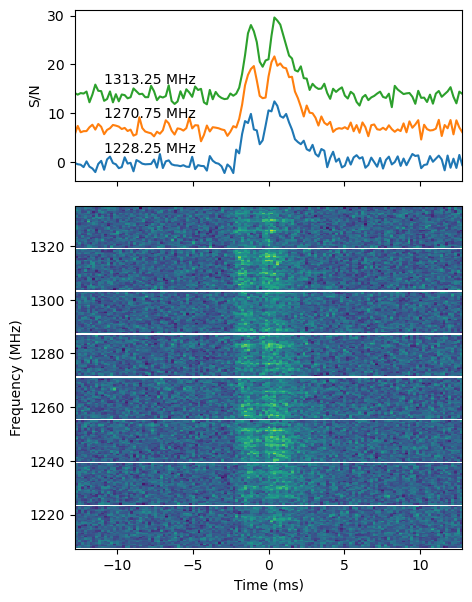

In [11]:
plot_burst(burst_downsamp,tdownsamp,freqs,sub_arr,ref_freqs,offset=7,vmax=5)

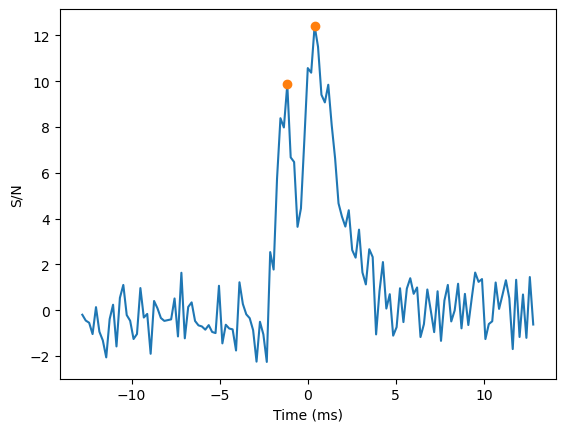

In [12]:
peaks = get_mu(tdownsamp,sub_arr[0],height=8,threshold=0.5,distance=5)

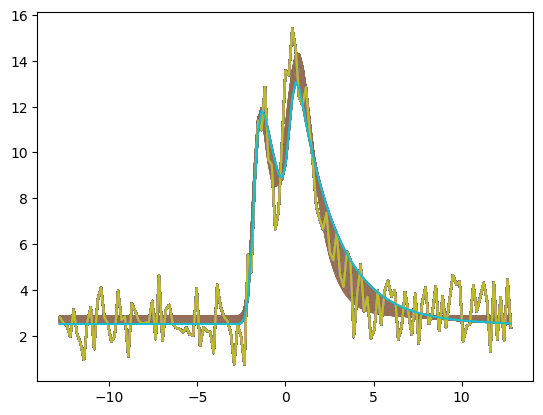

In [13]:
p0=[tdownsamp[peaks[0]],0.5,4,0,tdownsamp[peaks[1]],0.6,1.4]
bounds=[(tdownsamp[peaks[0]]-0.25,0.2,1.5,-inf,tdownsamp[peaks[1]]-0.25,0.05,-inf),(tdownsamp[peaks[0]]+0.25,5,+inf,+inf,tdownsamp[peaks[1]]+0.25,5,+inf)]
taumin = 0.9
taumax = 2.2
tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr = fit_tau(taumin,taumax,3,tdownsamp,sub_arr,ref_freqs,peaks,p0,bounds)

tau =  1.3442211055276383  +/-  0.3150753768844221


(41.0, 48.0)

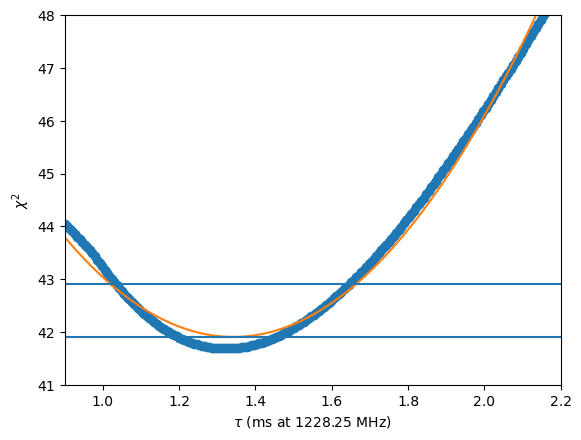

In [14]:
print_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr)
xlim(0.9,2.2)
ylim(41,48)

In [7]:
def plot_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub,offset,vmax,text_offset,outname):
    '''
    plots best-fit burst model
    args:
        tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr = outputs of fit_tau()
        nsub = # subbands + 1
        offset = vertical offset between subbanded profiles (roughly, S/N units)
        vmax = vmax for imshow()
        text_offset = vertical offset between central frequency labels and subbanded profiles
        outname = output file name
    '''
    
    fig,axs = subplots(nrows=2,height_ratios=(1.5,2),sharex=True,figsize=(4,6))
    subplots_adjust(hspace=0.05)
    axs[1].imshow(burst_downsamp, aspect='auto', interpolation='none',vmax=vmax,origin='lower',extent=[tdownsamp[0],tdownsamp[-1],freqs[0],freqs[-1]])
    axs[1].set_xlabel('Time (ms)',fontsize=12)
    axs[1].set_ylabel('Frequency (MHz)',fontsize=12)

    tau = tau_arr[argmin(chisq_arr)]
    def pulse_shape1(x, mu, sig, A, F, mu2, sig2, A2):
        half = int(len(x)/2)
        ex = piecewise(x,[x<mu,x>=mu],[0,exp(-x[x>=mu]/tau)])
        gauss = exp(-power(x - mu, 2.) / (2 * power(sig, 2.)))
        full = np.convolve(ex,gauss,mode='same')
    
        ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
        gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
        full2 = np.convolve(ex2,gauss2,mode='same')
        return A*full + A2*full2 + F

    floor = 0
    popt_top = popt_arr_top[argmin(chisq_arr)]
    axs[0].plot(tdownsamp,sub_arr[0],lw=2,label=str(round(ref_freqs[0],2))+' MHz')
    axs[0].plot(tdownsamp,pulse_shape1(tdownsamp,*popt_arr_top[argmin(chisq_arr)])-3,color='k')
    axs[0].text(0.25*max(tdownsamp),floor+text_offset,str(round(ref_freqs[0],2))+' MHz',fontsize=11)

    mu = popt_top[0]
    mu2 = popt_top[4]
    F = popt_top[3]

    for i in range(1,nsub-1):
        tau = tau_arr[argmin(chisq_arr)]*(ref_freqs[i]/ref_freqs[0])**(-4)

        def pulse_shape2(x, A1, A2, sig1, sig2):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu,x>=mu],[0,exp(-x[x>=mu]/tau)])
            gauss = exp(-power(x - mu, 2.) / (2 * power(sig1, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')
            return A1*full + A2*full2 + F

        floor = i*offset
        axs[0].plot(tdownsamp,sub_arr[i]+floor,lw=2)
        axs[0].plot(tdownsamp,pulse_shape2(tdownsamp,*popt_arr[argmin(chisq_arr),i-1,:])-3+floor,color='k')
        axs[0].text(0.25*max(tdownsamp),floor+text_offset,str(round(ref_freqs[i],2))+' MHz',fontsize=11)

    axs[0].set_ylabel('Intensity (arb.)',fontsize=12)
    axs[0].text(-12,32,r'$\tau = 1.3\pm0.3$ ms',fontsize=11)
    #tight_layout()
    savefig(outname+'.pdf')

    return

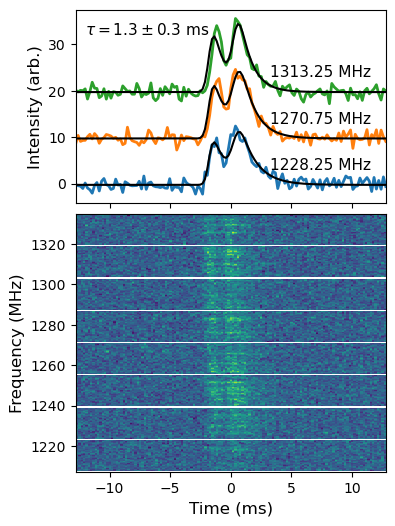

In [15]:
plot_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub=3+1,offset=10,vmax=5,text_offset=3,outname='B02')

In [17]:
# burst W01
f2 = data_path+'p55025_28_1us_500KHz_StokesI_DM464857.cor_Wb.fil'
freqs,tarr,burst_downsamp,ref_freqs,tdownsamp,sub_arr = read_data(f2,700,2,1,shift='left')

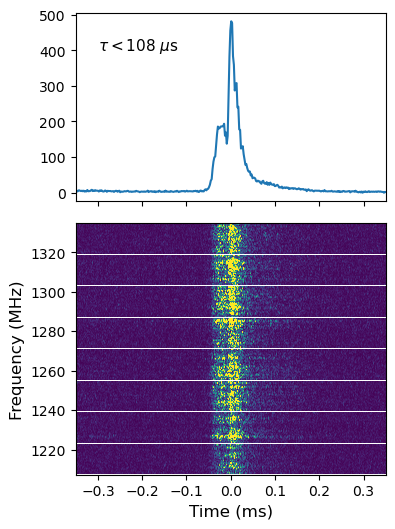

In [18]:
fig,axs = subplots(nrows=2,height_ratios=(1.5,2),sharex=True,figsize=(4,6))
subplots_adjust(hspace=0.1)
axs[1].imshow(burst_downsamp, aspect='auto', interpolation='none',vmax=30,origin='lower',extent=[tdownsamp[0],tdownsamp[-1],freqs[0],freqs[-1]])
axs[0].plot(tdownsamp,sub_arr[0])
    
axs[1].set_xlabel('Time (ms)',fontsize=12)
axs[1].set_ylabel('Frequency (MHz)',fontsize=12)

axs[0].text(-0.3,400,r'$\tau < 108$ $\mu$s',fontsize=11)
savefig('B01.pdf')

In [19]:
# burst 6
f3 = data_path+'p55049_25_1us_500KHz_StokesI_DM465095.cor_Wb.fil'
freqs,tarr,burst_downsamp,ref_freqs,tdownsamp,sub_arr = read_data(f3,1500,6,4,shift='right')

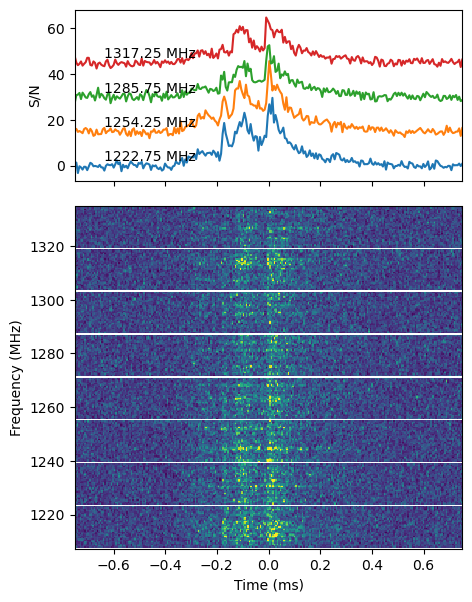

In [20]:
plot_burst(burst_downsamp,tdownsamp,freqs,sub_arr,ref_freqs,15,vmax=4)

In [25]:
def fit_tau3(taumin,taumax,nsub,tarr,subarr,ref_freqs,peaks,p01,bounds1):

    '''
    fits for tau using same framework as fit_tau(), but accommodates a 5-component burst
    '''

    tau_arr = linspace(taumin,taumax,100)
    nparam_top = 16
    popt_arr_top = zeros((len(tau_arr),nparam_top)) # number of free parameters is different for highest subband
    pcov_arr_top = zeros((len(tau_arr),nparam_top))
    nparam = 10
    popt_arr = zeros((len(tau_arr),nsub-1,nparam))
    pcov_arr = zeros((len(tau_arr),nsub-1,nparam))
    chisqall_arr = zeros((nsub,len(tau_arr)))
    
    for i in range(len(tau_arr)):
    
        # initial guess for mu1, mu2
        tau = tau_arr[i]

        def pulse_shape51(x, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3, mu4, sig4, A4, mu5, sig5, A5):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
            gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')

            ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
            gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
            full3 = np.convolve(ex3,gauss3,mode='same')

            ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
            gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
            full4 = np.convolve(ex4,gauss4,mode='same')

            gauss5 = exp(-power(x - mu5, 2.) / (2 * power(sig5, 2.)))
            
            return A1*full + A2*full2 + A3*full3 + A4*full4 + A5*gauss5 + F1

        sub1 = subarr[0]+10
        popt,pcov = curve_fit(pulse_shape51,tarr,sub1,p0=p01,bounds=bounds1)

        plot(tarr,sub1)
        plot(tarr,pulse_shape51(tarr,*popt))

        # initialize guesses for next subbands
        popt_set = np.copy(popt)
        mu1 = popt_set[0]
        sig1guess = popt_set[1]
        mu2 = popt_set[4]
        sig2guess = popt_set[5]
        mu3 = popt_set[7]
        sig3guess = popt_set[8]
        mu4 = popt_set[10]
        sig4guess = popt_set[11]
        mu5 = popt_set[13]
        sig5guess = popt_set[14]
        F = popt_set[3]
        A1guess = popt_set[2]
        A2guess = popt_set[6]
        A3guess = popt_set[9]
        A4guess = popt_set[12]
        A5guess = popt_set[15]

        popt_arr_top[i,:] = popt
        pcov_arr_top[i,:] = sqrt(diag(pcov))
        mod1 = pulse_shape51(tarr,*popt)
        chisq1,p1 = chisquare(sub1,(sum(sub1)/sum(mod1))*mod1)
        chisqall_arr[0,i] = chisq1
        freq1 = ref_freqs[0]

        for j in range(1,nsub):
            freq2 = ref_freqs[j]
            tau2 = tau*(freq2/freq1)**(-4)
            sub2 = subarr[j]+10

            def pulse_shape52(x,A1,A2,A3,A4,A5,sig1,sig2,sig3,sig4,sig5):
                half = int(len(x)/2)
                ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
                gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
                full = np.convolve(ex,gauss,mode='same')
    
                ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
                gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
                full2 = np.convolve(ex2,gauss2,mode='same')

                ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
                gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
                full3 = np.convolve(ex3,gauss3,mode='same')

                ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
                gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
                full4 = np.convolve(ex4,gauss4,mode='same')

                gauss5 = exp(-power(x - mu5, 2.) / (2 * power(sig5, 2.)))
                return A1*full + A2*full2 + A3*full3 + A4*full4 + A5*gauss5 + F

            popt2,pcov2 = curve_fit(pulse_shape52,tarr,sub2,p0=[A1guess,A2guess,A3guess,A4guess,A5guess,sig1guess,sig2guess,sig3guess,sig4guess,sig5guess],
                                    bounds=([-inf,-inf,-inf,-inf,-inf,sig1guess-(0.2*sig1guess),sig2guess-(0.2*sig2guess),sig3guess-(0.2*sig3guess),sig4guess-(0.2*sig4guess),sig5guess-(0.2*sig5guess)],
                                            [+inf,+inf,+inf,+inf,A5guess+0.1,sig1guess+(0.2*sig1guess),sig2guess+(0.2*sig2guess),sig3guess+(0.2*sig3guess),sig4guess+(0.2*sig4guess),sig5guess+(0.2*sig5guess)]))
            if j==3:
                popt2,pcov2 = curve_fit(pulse_shape52,tarr,sub2,p0=[A1guess-0.1,0,A3guess,A4guess,A5guess,sig1guess,sig2guess,sig3guess,sig4guess,sig5guess],
                                    bounds=([-inf,-inf,-inf,-inf,-inf,sig1guess-(0.2*sig1guess),sig2guess-(0.2*sig2guess),sig3guess-(0.2*sig3guess),sig4guess-(0.2*sig4guess),sig5guess-(0.2*sig5guess)],
                                            [A1guess-0.05,A2guess-0.8*A2guess,+inf,+inf,A5guess+0.1,sig1guess+(0.2*sig1guess),sig2guess+(0.2*sig2guess),sig3guess+(0.2*sig3guess),sig4guess+(0.2*sig4guess),sig5guess+(0.2*sig5guess)]))
            popt_arr[i,j-1,:] = popt2
            pcov_arr[i,j-1,:] = sqrt(diag(pcov2))
            modi = pulse_shape52(tarr,*popt2)
            chisq2,p2 = chisquare(sub2,(sum(sub2)/sum(modi))*modi)
            chisqall_arr[j,i] = chisq2
    
    chisq_arr = mean(chisqall_arr,axis=0)

    return tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr

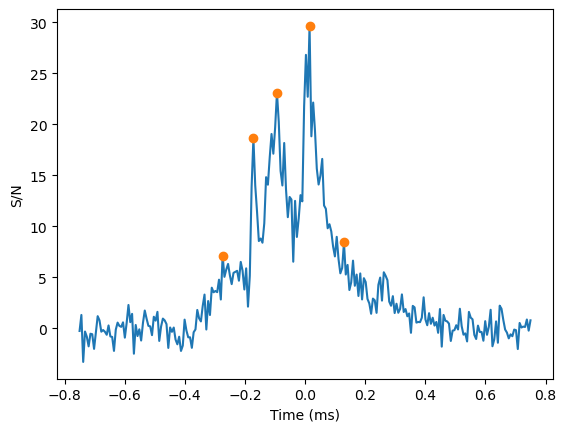

[-0.27409639 -0.17168675 -0.09337349  0.01506024]


In [28]:
peaks = get_mu(tdownsamp,sub_arr[0],height=5,threshold=2,distance=10) 
# exclude the last spurious peak
peaks = peaks[:-1]
print(tdownsamp[peaks])

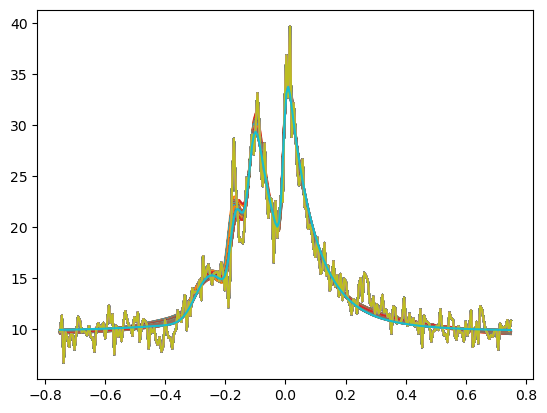

In [29]:
p0 = [tdownsamp[peaks[0]]+0.12,0.04,0.1,0,tdownsamp[peaks[1]]+0.075,0.015,0.7,tdownsamp[peaks[2]]+0.04,0.015,3,tdownsamp[peaks[3]]-0.02,0.01,12,tdownsamp[peaks[2]]+0.05,0.3,5] # 3 subbands
bounds1 = [p0[0]-0.1,p0[1]-0.2*abs(p0[1]),-inf,-inf,p0[4]-0.1,p0[5]-0.05*abs(p0[5]),-inf,p0[7]-0.1,p0[8]-0.2*abs(p0[8]),-inf,p0[10]-0.1,p0[11]-0.2*abs(p0[11]),-inf,p0[13]-0.1,p0[14]-0.2*abs(p0[14]),-inf]
bounds2 = [p0[0]+0.1,p0[1]+0.2*abs(p0[1]),+inf,+inf,p0[4]+0.1,p0[5]+0.05*abs(p0[5]),+inf,p0[7]+0.1,p0[8]+0.2*abs(p0[8]),+inf,p0[10]+0.1,p0[11]+0.2*abs(p0[11]),+inf,p0[13]+0.1,p0[14]+0.2*abs(p0[14]),+inf]#array(p0)+abs(0.2*array(p0))
bounds = [bounds1,bounds2]
taumin = 0.06
taumax = 0.085
tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr = fit_tau3(taumin,taumax,4,tdownsamp,sub_arr,ref_freqs,peaks,p0,bounds)

tau =  0.07515151515151516  +/-  0.007349246231155786


(40.0, 50.0)

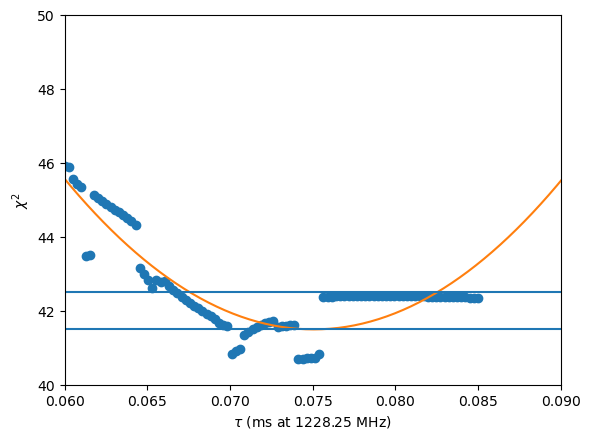

In [30]:
# the chi-square curve is messy, this is the case that I think has underestimated errors b/c the number of free parameters is large
print_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr)
xlim(0.06,0.09)
ylim(40,50)

In [26]:
def plot_results3(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub,offset,vmax,text_offset,outname):
    
    '''
    same as plot_results(), but for a 5-component burst
    '''
    
    fig,axs = subplots(nrows=2,height_ratios=(1.5,2),sharex=True,figsize=(4,6))
    subplots_adjust(hspace=0.05)
    axs[1].imshow(burst_downsamp, aspect='auto', interpolation='none',vmax=vmax,origin='lower',extent=[tdownsamp[0],tdownsamp[-1],freqs[0],freqs[-1]])
    axs[1].set_xlabel('Time (ms)',fontsize=12)
    axs[1].set_ylabel('Frequency (MHz)',fontsize=12)

    chi = polyfit(tau_arr,chisq_arr,2)
    chiz = poly1d(chi)
    tau = tau_arr[argmin(chiz(tau_arr))]
 
    def pulse_shape51(x, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3, mu4, sig4, A4, mu5, sig5, A5):
        half = int(len(x)/2)
        ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
        gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
        full = np.convolve(ex,gauss,mode='same')
    
        ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
        gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
        full2 = np.convolve(ex2,gauss2,mode='same')

        ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
        gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
        full3 = np.convolve(ex3,gauss3,mode='same')

        ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
        gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
        full4 = np.convolve(ex4,gauss4,mode='same')

        gauss5 = exp(-power(x - mu5, 2.) / (2 * power(sig5, 2.)))
            
        return A1*full + A2*full2 + A3*full3 + A4*full4 + A5*gauss5 + F1


    floor = 0
    popt_top = popt_arr_top[argmin(chisq_arr)]
    axs[0].plot(tdownsamp,sub_arr[0],lw=2,label=str(round(ref_freqs[0],2))+' MHz')
    axs[0].plot(tdownsamp,pulse_shape51(tdownsamp,*popt_arr_top[argmin(chisq_arr)])-10,color='k')
    axs[0].text(0.2*max(tdownsamp),floor+text_offset,str(round(ref_freqs[0],2))+' MHz',fontsize=11)

    mu1 = popt_top[0]
    mu2 = popt_top[4]
    mu3 = popt_top[7]
    mu4 = popt_top[10]
    mu5 = popt_top[13]
    F = popt_top[3]

    for i in range(1,nsub-1):
        tau = tau_arr[argmin(chisq_arr)]*(ref_freqs[i]/ref_freqs[0])**(-4)

        def pulse_shape52(x,A1,A2,A3,A4,A5,sig1,sig2,sig3,sig4,sig5):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
            gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')

            ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
            gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
            full3 = np.convolve(ex3,gauss3,mode='same')

            ex4 = piecewise(x,[x<mu4,x>=mu4],[0,exp(-x[x>=mu4]/tau)])
            gauss4 = exp(-power(x - mu4, 2.) / (2 * power(sig4, 2.)))
            full4 = np.convolve(ex4,gauss4,mode='same')

            gauss5 = exp(-power(x - mu5, 2.) / (2 * power(sig5, 2.)))
            return A1*full + A2*full2 + A3*full3 + A4*full4 + A5*gauss5 + F


        floor = i*offset
        axs[0].plot(tdownsamp,sub_arr[i]+floor,lw=2)
        axs[0].plot(tdownsamp,pulse_shape52(tdownsamp,*popt_arr[argmin(chisq_arr),i-1,:])-10+floor,color='k')
        axs[0].text(0.2*max(tdownsamp),floor+text_offset,str(round(ref_freqs[i],2))+' MHz',fontsize=11)

    axs[0].set_ylabel('Intensity (arb.)',fontsize=12)
    axs[0].text(-0.7,72,r'$\tau = 75\pm7$ $\mu$s',fontsize=11)
    #tight_layout()
    savefig(outname+'.pdf')

    return

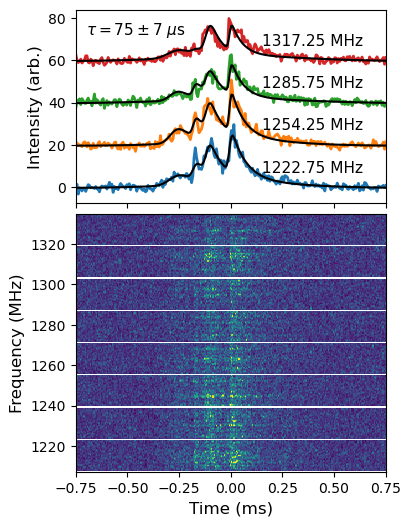

In [31]:
plot_results3(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub=5,offset=20,vmax=5,text_offset=7,outname='B06')

In [32]:
# B11
f7 = data_path+'p55081_19_1us_500KHz_StokesI_DM465266.cor_Wb.fil'
freqs,tarr,burst_downsamp,ref_freqs,tdownsamp,sub_arr = read_data(f7,2000,6,3,shift='none')

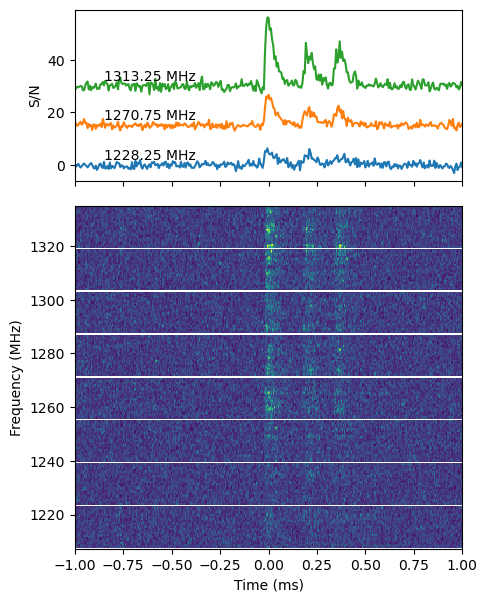

In [33]:
plot_burst(burst_downsamp,tdownsamp,freqs,sub_arr,ref_freqs,15,vmax=5)

In [35]:
def fit_tau4(taumin,taumax,nsub,tarr,subarr,ref_freqs,peaks,p01,bounds1):

    '''
    same as fit_tau(), but for a three-component burst
    note the ordering of the subbands was switched here b/c the burst is much brighter at the top of the band than at the bottom
    '''

    tau_arr = linspace(taumin,taumax,100)
    nparam_top = 10
    popt_arr_top = zeros((len(tau_arr),nparam_top)) # number of free parameters is different for highest subband
    pcov_arr_top = zeros((len(tau_arr),nparam_top))
    nparam = 6
    popt_arr = zeros((len(tau_arr),nsub-1,nparam))
    pcov_arr = zeros((len(tau_arr),nsub-1,nparam))
    chisqall_arr = zeros((nsub,len(tau_arr)))
    
    for i in range(len(tau_arr)):
    
        # initial guess for mu1, mu2
        tau = tau_arr[i]

        def pulse_shape31(x, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
            gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')

            ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
            gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
            full3 = np.convolve(ex3,gauss3,mode='same')
            
            return A1*full + A2*full2 + A3*full3 + F1

        sub1 = subarr[0]+10
        popt,pcov = curve_fit(pulse_shape31,tarr,sub1,p0=p01,bounds=bounds1)

        plot(tarr,sub1)
        plot(tarr,pulse_shape31(tarr,*popt))

        # initialize guesses for next subbands
        popt_set = np.copy(popt)
        mu1 = popt_set[0]
        sig1guess = popt_set[1]
        mu2 = popt_set[4]
        sig2guess = popt_set[5]
        mu3 = popt_set[7]
        sig3guess = popt_set[8]
        F = popt_set[3]
        A1guess = popt_set[2]
        A2guess = popt_set[6]*2
        A3guess = popt_set[9]*2

        popt_arr_top[i,:] = popt
        pcov_arr_top[i,:] = sqrt(diag(pcov))
        mod1 = pulse_shape31(tarr,*popt)
        chisq1,p1 = chisquare(sub1,(sum(sub1)/sum(mod1))*mod1)
        chisqall_arr[0,i] = chisq1
        freq1 = ref_freqs[0]

        for j in range(1,nsub):
            freq2 = ref_freqs[j]
            tau2 = tau*(freq2/freq1)**(4)
            sub2 = subarr[j]+10

            def pulse_shape32(x,A1,A2,A3,sig1,sig2,sig3):
                half = int(len(x)/2)
                ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
                gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
                full = np.convolve(ex,gauss,mode='same')
    
                ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
                gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
                full2 = np.convolve(ex2,gauss2,mode='same')

                ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
                gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
                full3 = np.convolve(ex3,gauss3,mode='same')

                return A1*full + A2*full2 + A3*full3 + F


            popt2,pcov2 = curve_fit(pulse_shape32,tarr,sub2,p0=[A1guess,A2guess,A3guess,sig1guess,sig2guess,sig3guess],
                                    bounds=([-inf,10,20,sig1guess-(0.1*sig1guess),sig2guess-(0.8*sig2guess),sig3guess-(0.8*sig3guess)],
                                            [+inf,+inf,+inf,sig1guess+(0.1*sig1guess),sig2guess+(0.8*sig2guess),sig3guess+(0.8*sig3guess)]))
        
            popt_arr[i,j-1,:] = popt2
            pcov_arr[i,j-1,:] = sqrt(diag(pcov2))
            modi = pulse_shape32(tarr,*popt2)
            chisq2,p2 = chisquare(sub2,(sum(sub2)/sum(modi))*modi)
            chisqall_arr[j,i] = chisq2
    
    chisq_arr = mean(chisqall_arr,axis=0)

    return tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr

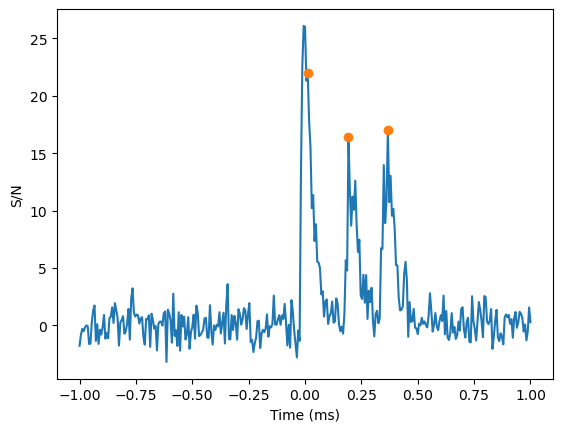

In [36]:
peaks = get_mu(tdownsamp,sub_arr[2],height=10,threshold=0.5,distance=15) 

In [37]:
# reverse the subbands to get initial parameters at highest S/N
sub_arr2 = sub_arr[::-1,:]
ref_freqs2 = ref_freqs[::-1]

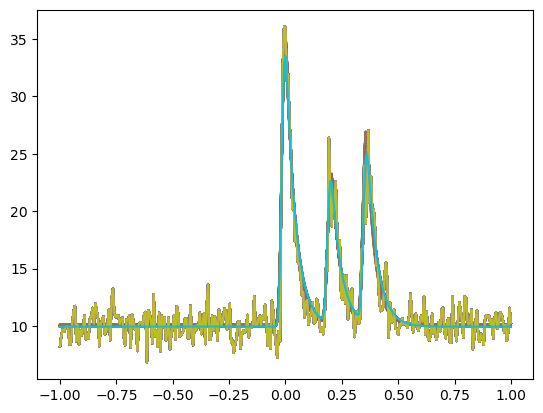

In [38]:
p0=[tdownsamp[peaks[0]]-0.02,0.01,6,0,tdownsamp[peaks[1]]-0.1,0.01,50,tdownsamp[peaks[2]]-0.19,0.01,400]
bounds1 = [p0[0]-0.1,p0[1]-0.2*abs(p0[1]),-inf,-inf,p0[4]-0.1,p0[5]-0.05*abs(p0[5]),30,p0[7]-0.1,p0[8]-0.2*abs(p0[8]),50]
bounds2 = [p0[0]+0.1,p0[1]+0.2*abs(p0[1]),+inf,+inf,p0[4]+0.1,p0[5]+0.05*abs(p0[5]),+inf,p0[7]+0.1,p0[8]+0.2*abs(p0[8]),+inf]
bounds = [bounds1,bounds2]
taumin = 0.035
taumax = 0.044
tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr = fit_tau4(taumin,taumax,3,tdownsamp,sub_arr2,ref_freqs2,peaks,p0,bounds)

tau =  0.040090909090909094  +/-  0.006702261306532665


(36.0, 38.0)

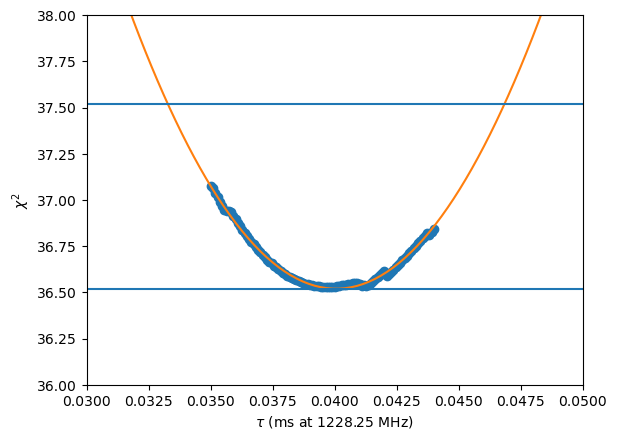

In [39]:
print_results(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr)
xlim(0.03,0.05)
ylim(36,38)

In [40]:
def plot_results4(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub,offset,vmax,text_offset,outname):
    
    fig,axs = subplots(nrows=2,height_ratios=(1.5,2),sharex=True,figsize=(4,6))
    subplots_adjust(hspace=0.05)
    axs[1].imshow(burst_downsamp[:,80:], aspect='auto', interpolation='none',vmax=vmax,origin='lower',extent=[tdownsamp[80],tdownsamp[-1],freqs[0],freqs[-1]])
    axs[1].set_xlabel('Time (ms)',fontsize=12)
    axs[1].set_ylabel('Frequency (MHz)',fontsize=12)

    chi = polyfit(tau_arr,chisq_arr,2)
    chiz = poly1d(chi)
    tau = tau_arr[argmin(chiz(tau_arr))]
    #tau = tau_arr[argmin(tau_arr)]
 
    def pulse_shape31(x, mu1, sig1, A1, F1, mu2, sig2, A2, mu3, sig3, A3):
        half = int(len(x)/2)
        ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
        gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
        full = np.convolve(ex,gauss,mode='same')
    
        ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
        gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
        full2 = np.convolve(ex2,gauss2,mode='same')

        ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
        gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
        full3 = np.convolve(ex3,gauss3,mode='same')
            
        return A1*full + A2*full2 + A3*full3


    floor = nsub*offset
    popt_top = popt_arr_top[argmin(chisq_arr)]
    axs[0].plot(tdownsamp[80:],sub_arr2[0][80:]+floor,lw=2,label=str(round(ref_freqs[0],2))+' MHz')
    axs[0].plot(tdownsamp[80:],floor+pulse_shape31(tdownsamp,*popt_arr_top[argmin(chisq_arr)])[80:],color='k')
    axs[0].text(0.43*max(tdownsamp),floor+text_offset,str(round(ref_freqs2[0],2))+' MHz',fontsize=11)

    mu1 = popt_top[0]
    mu2 = popt_top[4]
    mu3 = popt_top[7]
    F = popt_top[3]

    for i in range(1,nsub-1):
        tau = tau_arr[argmin(chisq_arr)]*(ref_freqs2[i]/ref_freqs2[0])**(4)

        def pulse_shape32(x,A1,A2,A3,sig1,sig2,sig3):
            half = int(len(x)/2)
            ex = piecewise(x,[x<mu1,x>=mu1],[0,exp(-x[x>=mu1]/tau)])
            gauss = exp(-power(x - mu1, 2.) / (2 * power(sig1, 2.)))
            full = np.convolve(ex,gauss,mode='same')
    
            ex2 = piecewise(x,[x<mu2,x>=mu2],[0,exp(-x[x>=mu2]/tau)])
            gauss2 = exp(-power(x - mu2, 2.) / (2 * power(sig2, 2.)))
            full2 = np.convolve(ex2,gauss2,mode='same')

            ex3 = piecewise(x,[x<mu3,x>=mu3],[0,exp(-x[x>=mu3]/tau)])
            gauss3 = exp(-power(x - mu3, 2.) / (2 * power(sig3, 2.)))
            full3 = np.convolve(ex3,gauss3,mode='same')

            return A1*full + A2*full2 + A3*full3 


        floor = (nsub-i)*offset
        axs[0].plot(tdownsamp[80:],sub_arr2[i][80:]+floor,lw=2)
        axs[0].plot(tdownsamp[80:],pulse_shape32(tdownsamp,*popt_arr[argmin(chisq_arr),i-1,:])[80:]+floor,color='k')
        axs[0].text(0.43*max(tdownsamp),floor+text_offset,str(round(ref_freqs2[i],2))+' MHz',fontsize=11)

    axs[0].set_ylabel('Intensity (arb.)',fontsize=12)
    axs[0].text(0.45,80,r'$\tau = 40\pm7$ $\mu$s',fontsize=11)
    #tight_layout()
    savefig(outname+'.pdf')

    return

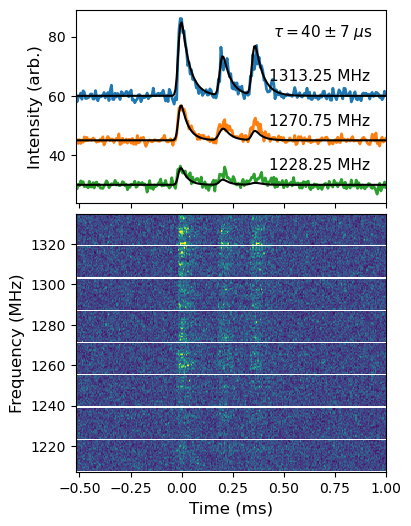

In [41]:
plot_results4(tau_arr,chisq_arr,popt_arr_top,pcov_arr_top,popt_arr,pcov_arr,nsub=4,offset=15,vmax=4,text_offset=5,outname='B11')